# Escenarios producción y simulación

Respondemos a las preguntas 3 y 4. Este notebook tiene tres partes: [escenarios e incertidumbre](#escenarios), [plan inicial de producción](#produccion) y [simulación física mensual](#simulacion). Los tres escenarios comparten el plan inicial y respetan el plazo de tres meses. Se mantienen las 1.000 réplicas y la semilla de la solución base.

Requiere [Modelo y validación](02_modelo_y_validacion.ipynb).

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

proyecto = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'src/rutas.py').is_file() and (p / 'data').is_dir()), None)
if proyecto is None:
    raise FileNotFoundError('Abre Jupyter desde la carpeta de entrega o desde notebooks.')
if str(proyecto) not in sys.path:
    sys.path.insert(0, str(proyecto))
from src.rutas import DATOS, RESULTADOS, leer_csv
assert DATOS.parent == proyecto, 'Los datos deben pertenecer a esta copia de entrega.'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                    'axes.spines.right': False, 'font.size': 11, 'axes.titlesize': 13})
print('Datos originales: data/. Resultados: resultados/.')


Datos originales: data/. Resultados: resultados/.


<a id="escenarios"></a>

## A Escenarios e incertidumbre

**Objetivo:** transformar la base de [Previsión y validación](02_modelo_y_validacion.ipynb) en tres historias cuantificadas de A013 y generar 1.000 años posibles dentro de cada una.

Una previsión central no expresa cuánto puede variar el año. Aquí distinguimos dos preguntas: **qué cambia si cambia el contexto** y **cuánto puede variar la demanda incluso con ese contexto fijado**. Los escenarios contestan la primera; los errores aleatorios, la segunda.

Esta etapa queda completa como análisis de demanda y preparación de entradas. El modelo del notebook 02 sigue siendo provisional: no superó la referencia en el total comparable de A012. Los intervalos que obtendremos dependen de ese modelo y de nuestras hipótesis. No son una promesa de ventas ni una garantía de cobertura futura.

Fuente del alcance: enunciado, tabla 4 y apartados 9.2–9.3 (enunciado original del caso). La simulación de stock, producción y margen corresponde a las siguientes etapas.

### 1. Escenario, réplica y percentil

- Un **escenario** fija una historia: paro, crédito, turismo, caída tras el adelanto, producto, costes y suministro.
- Una **réplica** es un año aleatorio completo dentro de esa historia. Cada mes puede apartarse de su demanda media.
- Un **percentil** describe esas réplicas: aproximadamente el 5% de las réplicas queda en P5 o por debajo; P95 deja aproximadamente un 5% por encima.

P5–P95 contiene el 90% central de nuestra distribución anual simulada, **condicionado a la historia y al método**. No significa que con un 90% de certeza la realidad vaya a caer ahí. No hemos probado la cobertura futura ni asignado probabilidades a los escenarios. No calculamos un promedio de las tres historias.

La **demanda media** es el centro previsto del escenario. La **media simulada** puede diferir ligeramente por remuestreo y redondeo. La mediana P50 tampoco tiene por qué coincidir con la media: las distribuciones multiplicativas suelen tener una cola superior más larga.

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
from src.escenarios import (ejecutar_escenarios, cargar_prevision, ORDEN)
from src.prevision import SEGMENTOS, huellas

datos_03 = cargar_prevision()  # Comprueba las huellas de datos y salidas del notebook 02.
salida = RESULTADOS / '04_escenarios_incertidumbre'
salida.mkdir(parents=True, exist_ok=True)
fichas = leer_csv('segmentos.csv')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titlesize': 13})
fmt = lambda x, n=0: f'{x:,.{n}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
config, tablas, simuladas = ejecutar_escenarios()
print('Forma de las réplicas:', simuladas.shape, '= escenarios × réplicas × meses × segmentos')
print('Semilla:', config['semilla'], '| Bloque:', config['bloque_meses'], 'meses')

Forma de las réplicas: (3, 1000, 12, 7) = escenarios × réplicas × meses × segmentos
Semilla: 42 | Bloque: 3 meses


### 2. Dónde entra cada suceso

| Tipo de cambio | Parte que se modifica | Ejemplo |
|---|---|---|
| Economía, calendario, turismo y normativa comercial | Mercado previsto | Más paro, menos viajeros o seis meses de caída. |
| Producto | Cuota de Kaido | Mejor aceptación de códigos nuevos o retraso comercial. |
| Arancel, cambio y prima de CO2 | Coste por coche | Se guardan para el cálculo posterior de margen. |
| Falta de piezas y capacidad | Fabricación y llegadas | Se guardan para modificar oferta, no compradores. |

Una fábrica parada **no elimina el deseo de comprar**. Puede impedir satisfacerlo; eso aparecerá en ventas perdidas y transfers al simular stock. Del mismo modo, un arancel no reduce automáticamente la demanda: aquí se supone que no se repercute al precio del cliente. Si más adelante suponemos esa repercusión, necesitaremos otra hipótesis comercial explícita.

Los tres escenarios compartirán el plan inicial pensado para el central en el bloque de producción. En esta etapa no fabricamos un plan distinto para cada historia, ni calculamos todavía ventas realizadas, stock o beneficio.

### 3. Hipótesis cuantificadas y origen

| Suceso | Pesimista | Central | Optimista | Origen y límite |
|---|---|---|---|---|
| Paro | +2 puntos porcentuales | Q4 de A012 | −1 punto | Tamaños propuestos en tabla 4. No son cambios relativos del 2% y 1%. |
| Crédito | Sin cambio | Q4 de A012 | −1 punto porcentual | El caso dice que se abarata; el tamaño es supuesto. |
| Combustible | −3 puntos de confianza | Sin cambio | +3 puntos de confianza | No hay serie de combustible; proxy supuesto para confianza, sin afirmar una elasticidad de gasolina. |
| Viajeros | −5 puntos de variación anual | Media de A012 | +5 puntos | Supuesto, comparado con cambios históricos más abajo. |
| Caída tras adelanto | Enero–junio | Enero–marzo | Solo enero | Duraciones de la tabla 4. No se traslada un número exacto de ventas de A012. |
| Plan de ayuda | Sin ayuda | Sin ayuda | Abril–diciembre, particulares | Existencia de ayuda sugerida por el caso; comienzo y duración supuestos. |
| Nuevos códigos | MSUV se retrasa abril→julio | Llegan en abril y sostienen cuota | +10% de cuota, ponderado por códigos nuevos | Fechas y magnitudes supuestas. Los códigos disponibles sí están en `segmentos.csv`. |
| Retraso comercial | −5% de cuota × peso de códigos nuevos MSUV, abril–junio | Ninguno | Ninguno | Penalización supuesta, independiente del problema de piezas. |
| Arancel adicional | 3% del PFF | 0 | 0 | Proxy de coste: no se conoce una base aduanera ni tipo adicional real. |
| Prima de CO2 | 100% de la prima del segmento | No cargada | No cargada | Importe por coche del caso; asignación central/optimista supuesta. |
| Euro | Sin ahorro | Sin ahorro | Ahorro de 1% del PFF | Proxy de coste supuesto, no una serie de tipo de cambio estimada. |
| Suministro | MSUV pierde fabricación de junio; llegada afectada en septiembre | Sin parada | Capacidad ×1,20 | Segmento, mes y 20% son supuestos. Capacidad sobrante no fabrica coches automáticamente. |

La base económica conserva Q4 de A012, salvo turismo, que conserva la media anual. No añadimos además otra penalización general de “pesimismo”: los efectos ya entran por sus variables y duplicarlos inflaría la diferencia.

Todas las cantidades editables están en [configuracion/escenarios_A013.json](../configuracion/escenarios_A013.json). Cambia ese único archivo y vuelve a ejecutar este notebook. Las funciones están en [src/escenarios.py](../src/escenarios.py). No hay que cambiar tablas a mano.

In [3]:
resumen_supuestos = pd.DataFrame(config['escenarios']).T
display(resumen_supuestos[['paro_pp', 'credito_pp', 'confianza_puntos_geopolitica', 'viajeros_pp',
                           'caida_meses', 'ayuda_desde_mes', 'mejora_producto_pct', 'retraso_meses']])
macro_historica = leer_csv('macro_mensual.csv')
anios_macro = macro_historica.groupby('anio')[['paro', 'tipo_credito_consumo', 'viajeros_var']].mean()
cambios = anios_macro.diff().dropna()
display(cambios.agg(['min', 'median', 'max']).T.round(2).rename_axis('Variable'))
display((anios_macro.loc['A005'] - anios_macro.loc['A004']).rename('Cambio medio A004→A005').round(2).to_frame())
print('Referencias descriptivas: no garantizan que los shocks tengan idéntico efecto en A013.')

,paro_pp,credito_pp,confianza_puntos_geopolitica,viajeros_pp,caida_meses,ayuda_desde_mes,mejora_producto_pct,retraso_meses
Pesimista,2.0,0.0,-3.0,-5.0,6,None,0.0,3
Central,0.0,0.0,0.0,0.0,3.0,NaN,0.0,0.0
Optimista,-1.0,-1.0,3.0,5.0,1.0,4.0,0.1,0.0


,min,median,max
Variable,,,
paro,-2.42,-1.15,6.61
tipo_credito_consumo,-1.98,-0.19,0.58
viajeros_var,-6.37,1.15,12.98


,Cambio medio A004→A005
paro,3.40
tipo_credito_consumo,0.58
viajeros_var,-6.37


Referencias descriptivas: no garantizan que los shocks tengan idéntico efecto en A013.


### 4. Producto: no confundir nuevos códigos con crecimiento garantizado

Dos códigos nuevos entre cuatro en MSUV representan un peso del 50%. Una mejora supuesta del 10% da un **5% de mejora de cuota** desde el mes de lanzamiento, no un 10% de todas las ventas anuales. En CSUV son dos entre tres: el mismo supuesto eleva su cuota un 6,67% desde abril. Es una ponderación sencilla por número de códigos; desconocemos su mezcla real de ventas.

Examinamos episodios de renovación con tres meses previos y tres posteriores completos. Comparamos la cuota agregada de cada ventana. Excluimos del resumen “sin sucesos” ventanas con ayudas, adelanto, caída o IVA marcados. Aun así pueden cambiar competencia, precios, stock y economía: el resultado **no es causal**. También hay renovaciones consecutivas cuyas ventanas se solapan; no son observaciones independientes.

El central no asigna una mejora automática: conserva la cuota con una gama renovada. El +10% optimista es una hipótesis de aceptación favorable que se compara con la dispersión de episodios históricos. La pérdida del retraso tampoco se deduce mecánicamente de ellos.

In [4]:
renovaciones = datos_03['renovaciones_historicas']
sin_sucesos = renovaciones[~renovaciones.hay_sucesos_en_ventana]
display(sin_sucesos[['segmento', 't', 'variacion_cuota_pct']].round(2))
display(sin_sucesos.variacion_cuota_pct.describe(percentiles=[.25, .5, .75]).round(2).to_frame())
print('Hipótesis optimista antes de ponderar por códigos: +10%. No es una estimación causal.')

,segmento,t,variacion_cuota_pct
0,B,36,-30.31
1,B,37,-29.39
3,B,91,90.48
4,B,112,-31.81
5,B,118,-30.04
8,C,37,-7.10
9,C,45,22.20
13,C,105,-11.86
18,MD,104,13.08
20,MSUV,52,194.84


,variacion_cuota_pct
count,16.00
mean,10.39
std,59.04
min,-31.81
25%,-25.37
50%,-8.49
75%,15.36
max,194.84


Hipótesis optimista antes de ponderar por códigos: +10%. No es una estimación causal.


### 5. Previsiones medias y efecto de cada hipótesis

Para cambiar el mercado usamos los coeficientes del notebook 02: si una variable cambia en Δ y su coeficiente es β, el componente `mercado + 1` se multiplica por `exp(β × Δ)`. Al volver a unidades se resta uno y se evita un valor negativo. Esto reproduce el modelo ajustado y su corrección de logaritmo; no volvemos a aprender coeficientes con cada escenario.

La cuota se modifica por producto y se limita al rango 0–1. Una predicción no puede superar el mercado de su segmento y canal. El escenario central de este notebook coincide exactamente con la base del notebook 02.

La descomposición añade cambios en el orden economía → combustible → turismo → duración de caída → ayuda → producto. Cada incremento se calcula después de los anteriores; los efectos interactúan, de modo que otro orden repartiría sus contribuciones de otra manera. El cambio total no depende de ese orden.

In [5]:
previsiones = tablas['prevision_escenarios_A013']
medias = previsiones.groupby(['segmento', 'escenario']).demanda_media.sum().unstack('escenario')[ORDEN]
medias.loc['TOTAL'] = medias.sum()
display(medias.round(1))
efectos = tablas['descomposicion_efectos']
display(efectos[efectos.segmento == 'TOTAL'][['escenario', 'componente', 'cambio_coches', 'demanda_despues']].round(1))
ayuda_ssuv = efectos[(efectos.escenario == 'Optimista') & (efectos.segmento == 'SSUV') & (efectos.componente == 'Plan de ayuda')].iloc[0]
display(Markdown(f'**Punto sensible:** la ayuda añade {fmt(ayuda_ssuv.cambio_coches)} clientes SSUV en esta cuenta incremental. Es una respuesta del modelo a pocos episodios históricos, no una garantía de que un plan futuro repita ese efecto.'))

escenario,Pesimista,Central,Optimista
segmento,,,
B,1494.8,1628.1,1993.7
C,3282.6,3584.5,4316.7
CSUV,2093.8,2293.5,2875.8
MD,656.0,751.9,856.9
MSUV,6567.8,7196.2,8793.2
S,519.4,694.1,892.0
SSUV,5684.0,6060.6,10206.1
TOTAL,20298.4,22208.8,29934.4


,escenario,componente,cambio_coches,demanda_despues
7,Pesimista,Economía,-854.1,21354.8
15,Pesimista,Combustible (proxy confianza),-554.6,20800.1
23,Pesimista,Turismo,-40.9,20759.2
31,Pesimista,Duración de caída,-421.7,20337.5
39,Pesimista,Plan de ayuda,0.0,20337.5
47,Pesimista,Producto,-39.1,20298.4
55,Optimista,Economía,2271.5,24480.3
63,Optimista,Combustible (proxy confianza),698.3,25178.7
71,Optimista,Turismo,45.7,25224.4
79,Optimista,Duración de caída,310.9,25535.2


**Punto sensible:** la ayuda añade 1.942 clientes SSUV en esta cuenta incremental. Es una respuesta del modelo a pocos episodios históricos, no una garantía de que un plan futuro repita ese efecto.

### 6. Cómo generamos la incertidumbre

Usamos los 36 meses de errores del notebook 02 que se calcularon sin entrenar ni elegir con el propio año que se preveía. Cada error se expresa como `log((real + 0,5) / (previsto + 0,5))`, después de sumar canales por mes y segmento. El 0,5 evita problemas con un cero; no son ventas añadidas al histórico.

Restamos la media de los errores de cada segmento para separar dispersión y sesgo. Luego remuestreamos **bloques circulares de tres meses**: elegimos al azar un inicio histórico y copiamos tres errores consecutivos; repetimos hasta completar doce meses. Al llegar al final de la muestra se vuelve al principio. Es una aproximación que conserva parte de la persistencia a corto plazo, no todo un ciclo económico.

**Todos los segmentos toman los mismos bloques.** Así se conservan shocks comunes y relaciones contemporáneas. Sortear cada segmento por separado podría subestimar o exagerar el riesgo del total. Los mismos sorteos se usan en los tres escenarios para que sus diferencias no se deban a distinto ruido aleatorio.

Pasamos del error logarítmico a un factor positivo y lo dividimos por su media exponencial histórica. Su media teórica queda en uno: multiplicar por él añade dispersión sin cambiar deliberadamente la media del escenario. Redondeamos al coche entero en cada mes y réplica.

**Límite importante:** centrar errores no corrige el sesgo del modelo. A012 mostró sobreestimación, especialmente en MD. Estos intervalos representan variación alrededor de la base reajustada, pero no incluyen toda la incertidumbre de escoger mal el modelo, repetir un cambio estructural o equivocarse en el escenario. La calibración tiene solo tres años y puede quedar corta ante un suceso nuevo. Los rangos anuales pueden ser mucho más estrechos que los mensuales porque unos errores se compensan con otros.

In [6]:
residuos = tablas['residuos_calibracion']
print('Ventana de calibración:', int(residuos.t.min()), 'a', int(residuos.t.max()))
display(tablas['correlacion_residuos'].set_index('segmento').round(2))
assert residuos.t.tolist() == list(range(109, 145))
assert simuladas.shape == (3, config['replicas'], 12, 7)
assert np.issubdtype(simuladas.dtype, np.integer) and simuladas.min() >= 0

Ventana de calibración: 109 a 144


segmento,B,C,MD,SSUV,CSUV,MSUV,S
segmento,,,,,,,
B,1.00,0.03,-0.23,0.23,0.39,0.31,-0.45
C,0.03,1.00,0.01,-0.27,-0.17,0.02,0.13
MD,-0.23,0.01,1.00,-0.26,-0.02,0.20,0.38
SSUV,0.23,-0.27,-0.26,1.00,0.63,-0.06,-0.59
CSUV,0.39,-0.17,-0.02,0.63,1.00,0.74,-0.50
MSUV,0.31,0.02,0.20,-0.06,0.74,1.00,-0.13
S,-0.45,0.13,0.38,-0.59,-0.50,-0.13,1.00


### 7. La incertidumbre especial de CSUV

CSUV no dispone de años completos comparables. No usaremos sus ceros anteriores al lanzamiento para fingir que conocemos su error. Le asignamos como **proxy** el promedio de errores logarítmicos de SSUV y MSUV: comparte parte del movimiento del mercado SUV.

Además aplicamos un factor lognormal de lanzamiento común a todo el año, de media uno y coeficiente de variación del **30%**. Es una hipótesis explícita sobre incertidumbre anual, no un dato estimado. Usar un solo factor anual evita que doce sorteos independientes hagan desaparecer artificialmente el riesgo de que el lanzamiento funcione peor durante todo el año.

La correlación de CSUV de la tabla anterior es construida por este proxy, no observada históricamente. Más abajo probamos 15%, 30% y 45%. Esta sensibilidad expresa cuánto depende el intervalo de una decisión nuestra; obtener más pedidos e información de mezcla comercial sería más útil que aumentar indefinidamente el número de réplicas.

In [7]:
anual = tablas['resumen_anual']
display(anual[['escenario', 'segmento', 'prevision_media', 'media_simulada', 'p05', 'p50', 'p95',
               'error_montecarlo_media']].round(1))
assert (anual.p05 <= anual.p50).all() and (anual.p50 <= anual.p95).all()
assert (simuladas[0] <= simuladas[1]).all() and (simuladas[1] <= simuladas[2]).all()

,escenario,segmento,prevision_media,media_simulada,p05,p50,p95,error_montecarlo_media
0,Pesimista,B,1494.8,1497.2,1232.0,1491.0,1772.0,5.3
1,Pesimista,C,3282.6,3306.8,2629.9,3334.0,3910.2,12.4
2,Pesimista,MD,656.0,655.1,523.0,661.0,768.0,2.3
3,Pesimista,SSUV,5684.0,5675.2,4833.8,5635.0,6544.1,16.5
4,Pesimista,CSUV,2093.8,2106.2,1195.0,2025.0,3306.1,20.2
5,Pesimista,MSUV,6567.8,6584.0,5378.7,6608.0,7646.0,21.4
6,Pesimista,S,519.4,520.4,312.0,513.0,785.0,4.6
7,Pesimista,TOTAL,20298.4,20344.9,18715.8,20333.0,22097.0,32.6
8,Central,B,1628.1,1631.0,1341.9,1625.0,1928.0,5.8
9,Central,C,3584.5,3610.7,2876.4,3641.5,4264.2,13.6


### 8. Cómo leer los resultados

En el gráfico anual cada punto es P50 y cada línea P5–P95. Cada segmento tiene su propia escala; compara las tres historias **dentro del mismo panel**. El total se calcula sumando todos los segmentos de cada réplica y luego obteniendo sus percentiles. **No se suman los percentiles de los segmentos**, porque eso ignoraría sus relaciones.

El gráfico mensual del total muestra bandas P10–P90, un intervalo central del 80% por mes, más estrecho que P5–P95. Estas bandas no son un intervalo simultáneo para los doce meses: que un mes esté dentro no garantiza que lo estén todos.

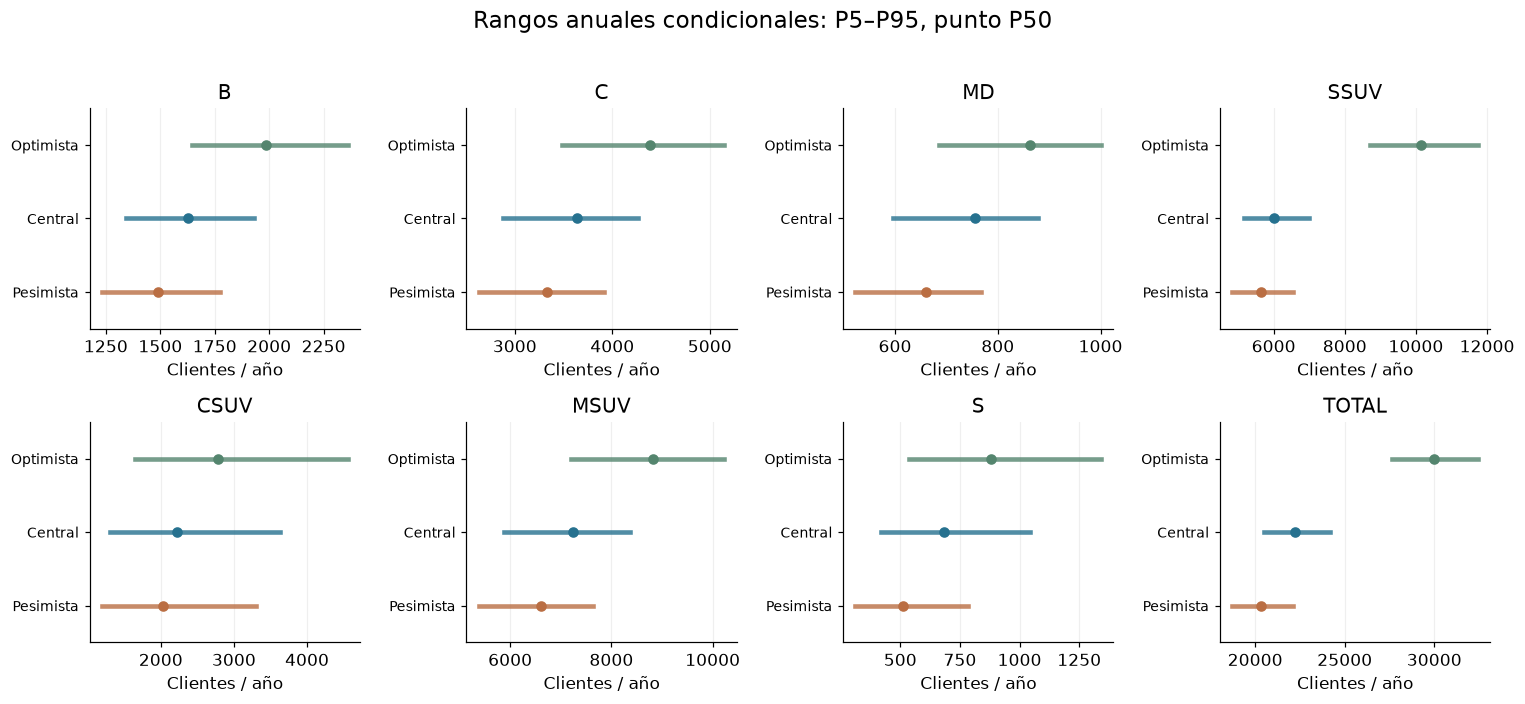

In [8]:
colores = {'Pesimista': '#BA6E43', 'Central': '#26718F', 'Optimista': '#54856E'}
fig, ejes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, segmento in zip(ejes.flat, SEGMENTOS + ['TOTAL']):
    for i, nombre in enumerate(ORDEN):
        r = anual[(anual.segmento == segmento) & (anual.escenario == nombre)].iloc[0]
        ax.plot([r.p05, r.p95], [i, i], lw=3, color=colores[nombre], alpha=.8)
        ax.scatter(r.p50, i, s=35, color=colores[nombre], zorder=3)
    ax.set(title=segmento, yticks=[0, 1, 2], yticklabels=ORDEN, ylim=(-.5, 2.5), xlabel='Clientes / año')
    ax.tick_params(axis='y', labelsize=9); ax.ticklabel_format(axis='x', style='plain')
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Rangos anuales condicionales: P5–P95, punto P50', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .96)); fig.savefig(salida / '01_rangos_anuales.png', dpi=160)
plt.show(); plt.close(fig)

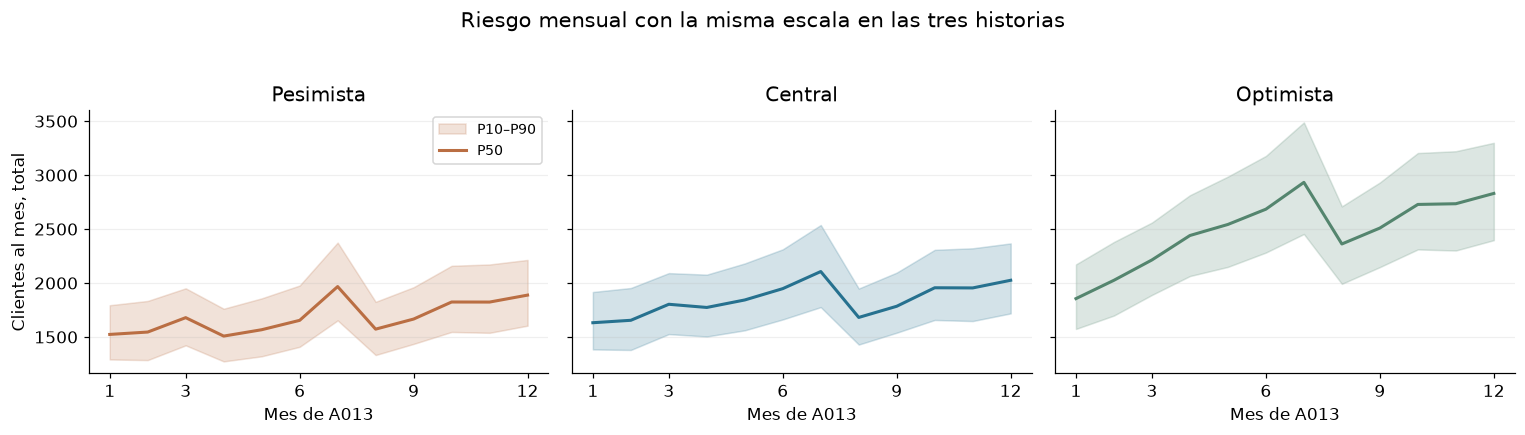

In [9]:
bandas = tablas['bandas_mensuales']
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, nombre in zip(ejes, ORDEN):
    z = bandas[(bandas.segmento == 'TOTAL') & (bandas.escenario == nombre)].sort_values('mes')
    ax.fill_between(z.mes, z.p10, z.p90, color=colores[nombre], alpha=.2, label='P10–P90')
    ax.plot(z.mes, z.p50, color=colores[nombre], lw=2, label='P50')
    ax.set(title=nombre, xticks=[1, 3, 6, 9, 12], xlabel='Mes de A013')
    ax.grid(axis='y', alpha=.2)
ejes[0].set_ylabel('Clientes al mes, total'); ejes[0].legend(fontsize=9)
fig.suptitle('Riesgo mensual con la misma escala en las tres historias', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .94)); fig.savefig(salida / '02_bandas_mensuales_total.png', dpi=160)
plt.show(); plt.close(fig)

### 9. Sensibilidad: cuánto depende de nuestras decisiones

La duración del efecto posterior al adelanto no se identifica con exactitud. Recalculamos el central con uno, tres y seis meses, dejando todo lo demás igual. También mantenemos la demanda media CSUV y cambiamos su incertidumbre anual adicional a 15%, 30% y 45%.

No son tres nuevas probabilidades ni se mezclan con los escenarios: son cambios de **una hipótesis cada vez**. La primera sensibilidad desplaza la media; la segunda cambia principalmente la amplitud del intervalo. Ambas merecen quedar visibles en una recomendación posterior.

,hipotesis,valor,demanda_total_central,csuv_media,csuv_p05,csuv_p95
0,Duración de caída central (meses),1.00,22502.58,2299.35,NaN,NaN
1,Duración de caída central (meses),3.00,22208.82,2293.49,NaN,NaN
2,Duración de caída central (meses),6.00,21757.88,2284.43,NaN,NaN
3,CV anual adicional CSUV,0.15,22208.82,2293.49,1718.85,2973.15
4,CV anual adicional CSUV,0.30,22208.82,2293.49,1307.95,3624.05
5,CV anual adicional CSUV,0.45,22208.82,2293.49,994.90,4306.45


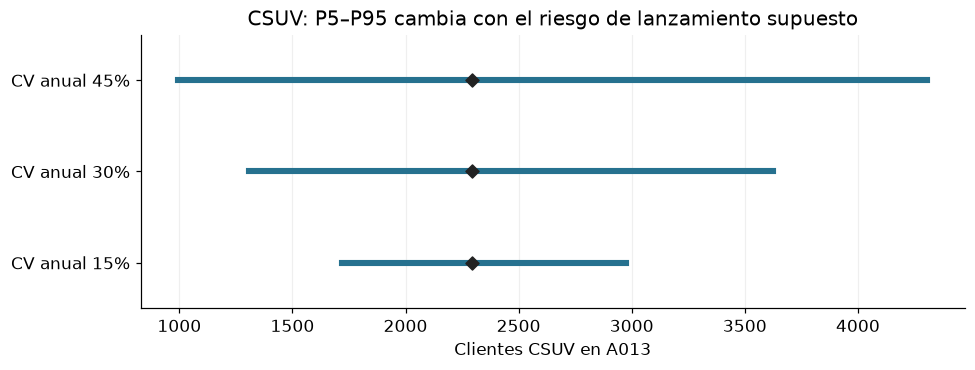

In [10]:
sensibilidad = tablas['sensibilidad_hipotesis']
display(sensibilidad.round(2))
z = sensibilidad[sensibilidad.hipotesis == 'CV anual adicional CSUV']
fig, ax = plt.subplots(figsize=(9, 3.5))
for i, (_, r) in enumerate(z.iterrows()):
    ax.plot([r.csuv_p05, r.csuv_p95], [i, i], lw=4, color='#26718F')
    ax.scatter(r.csuv_media, i, color='#222222', marker='D', zorder=3)
ax.set(yticks=range(3), yticklabels=[f'CV anual {v:.0%}' for v in z.valor], ylim=(-.5, 2.5),
       xlabel='Clientes CSUV en A013', title='CSUV: P5–P95 cambia con el riesgo de lanzamiento supuesto')
ax.grid(axis='x', alpha=.2)
fig.tight_layout(); fig.savefig(salida / '03_sensibilidad_CSUV.png', dpi=160)
plt.show(); plt.close(fig)

### 10. Entradas que guardamos para producción y margen

`entradas_costes.csv` contiene el coste adicional por coche de arancel, CO2 y ahorro de cambio. **No es el margen**: falta combinar ventas realizadas, beneficio bruto, VM, stock, transfer y demás costes. El PFF medio es solo una base proxy para dos de esos efectos.

`entradas_suministro.csv` identifica mes de fabricación, llegada tres meses después, factor de producción y capacidad. La parada de junio de MSUV reduce una fabricación; con nuestro plazo discreto afecta a septiembre. Las fabricaciones de octubre–diciembre pueden llegar en A014: se conservan sus contadores `t`, aunque la demanda simulada aquí termina en A013. El bloque de producción deberá definir el horizonte de continuación y el pipeline inicial.

Los barcos iniciales comprometidos no se conocen en un fichero: todavía hay que construir y justificar esa hipótesis en el bloque de producción. Una capacidad ×1,20 no significa fabricar un 20% más: solo permitirá cubrir pedidos si el modelo de producción lo decide. Todas las historias arrancarán del mismo plan central y solo ajustarán pedidos a tres meses vista.

In [11]:
display(tablas['entradas_costes'].round(2))
display(tablas['entradas_suministro'].query('factor_produccion < 1'))
archivo_replicas = salida / 'replicas_demanda_A013.npz'
with np.load(archivo_replicas, allow_pickle=False) as guardado:
    np.testing.assert_array_equal(guardado['demanda'], simuladas)
    print('Escenarios:', guardado['escenarios'].tolist())
    print('Segmentos:', guardado['segmentos'].tolist())
    print('Meses:', guardado['meses'].tolist())
metodo = json.loads((salida / 'metodo.json').read_text())
assert metodo['fuentes_sha256'] == huellas()
print('Réplicas guardadas y recuperadas sin pérdida. Fuentes originales sin cambios.')

,escenario,segmento,arancel_adicional_eur_coche_proxy,prima_co2_eur_coche,ahorro_cambio_eur_coche_proxy,coste_neto_adicional_eur_coche_proxy
0,Pesimista,B,409.32,2555.0,0.00,2964.32
1,Pesimista,C,619.38,1952.0,0.00,2571.38
2,Pesimista,MD,826.56,2082.0,0.00,2908.56
3,Pesimista,SSUV,564.57,2830.0,0.00,3394.57
4,Pesimista,CSUV,785.28,1912.0,0.00,2697.28
5,Pesimista,MSUV,772.14,4203.0,0.00,4975.14
6,Pesimista,S,745.29,4493.0,0.00,5238.29
7,Central,B,0.00,0.0,0.00,0.00
8,Central,C,0.00,0.0,0.00,0.00
9,Central,MD,0.00,0.0,0.00,0.00


,escenario,segmento,mes_fabricacion,t_fabricacion,t_llegada,factor_produccion,factor_capacidad
65,Pesimista,MSUV,6,150,153,0.0,1.0


Escenarios: ['Pesimista', 'Central', 'Optimista']
Segmentos: ['B', 'C', 'MD', 'SSUV', 'CSUV', 'MSUV', 'S']
Meses: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Réplicas guardadas y recuperadas sin pérdida. Fuentes originales sin cambios.


### 11. Reproducibilidad y tamaño de la simulación

La semilla 42 reproduce los sorteos. Cada escenario tiene 1.000 réplicas × 12 meses × 7 segmentos: 84.000 cantidades de demanda, 252.000 entre los tres. Las réplicas se guardan comprimidas, con sus etiquetas y sin objetos serializados, para que el bloque de producción pueda usarlas tal cual.

El **error Monte Carlo de la media** es la desviación anual entre réplicas dividida por la raíz del número de réplicas. Mide cuánto puede cambiar nuestra media por usar una muestra de sorteos. Es distinto del riesgo comercial: aumentar réplicas reduce ese error numérico, pero no corrige un modelo sesgado, una ayuda mal calibrada ni una fecha de lanzamiento desconocida.

Para repetir: reinicia el kernel y ejecuta todo. El bloque de escenarios lee los archivos del notebook 02 y sus huellas. Si las fuentes o resultados del notebook 02 han cambiado a mano, pedirá regenerarlos. La prueba de A012 se conserva; cambiar hipótesis de escenarios no selecciona modelos otra vez.

In [12]:
totales = anual[anual.segmento == 'TOTAL'].set_index('escenario').loc[ORDEN]
filas = [f'- **{nombre}:** media prevista {fmt(r.prevision_media)} clientes; P5–P95 de {fmt(r.p05)} a {fmt(r.p95)}.'
         for nombre, r in totales.iterrows()]
texto = '\n'.join([
    '### Conclusión de los escenarios', '', *filas, '',
    'Estos rangos son condicionales al modelo y a las hipótesis. No asignamos probabilidades a las historias ni afirmamos cobertura futura garantizada.', '',
    '**La demanda y sus escenarios están preparados; aún no son ventas, producción ni beneficio.** CSUV depende de una hipótesis anual de lanzamiento y el optimista es sensible al plan de ayudas, especialmente en SSUV.', '',
    'La base del notebook 02 no supera la referencia total en A012. Antes de aprobar producción hay que revisar ese modelo y validar mejor la evolución de cuota, la ayuda y los segmentos con errores grandes.', '',
    'El bloque de producción recibirá la base central, las réplicas conjuntas y los shocks de suministro. Tendrá que fijar el pipeline inicial, el stock de seguridad, la política de revisión y las llegadas a tres meses vista. El margen se calculará después con costes y ventas realizables.'
])
display(Markdown(texto))
(salida / 'conclusiones.md').write_text(texto + '\n')

### Conclusión de los escenarios

- **Pesimista:** media prevista 20.298 clientes; P5–P95 de 18.716 a 22.097.
- **Central:** media prevista 22.209 clientes; P5–P95 de 20.498 a 24.181.
- **Optimista:** media prevista 29.934 clientes; P5–P95 de 27.635 a 32.432.

Estos rangos son condicionales al modelo y a las hipótesis. No asignamos probabilidades a las historias ni afirmamos cobertura futura garantizada.

**La demanda y sus escenarios están preparados; aún no son ventas, producción ni beneficio.** CSUV depende de una hipótesis anual de lanzamiento y el optimista es sensible al plan de ayudas, especialmente en SSUV.

La base del notebook 02 no supera la referencia total en A012. Antes de aprobar producción hay que revisar ese modelo y validar mejor la evolución de cuota, la ayuda y los segmentos con errores grandes.

El bloque de producción recibirá la base central, las réplicas conjuntas y los shocks de suministro. Tendrá que fijar el pipeline inicial, el stock de seguridad, la política de revisión y las llegadas a tres meses vista. El margen se calculará después con costes y ventas realizables.

1113

<a id="produccion"></a>

## B Producción y stock

**Objetivo:** convertir la demanda del bloque de escenarios en un plan inicial común de fabricación, estimar las llegadas ya comprometidas y fijar un colchón de seguridad por segmento. El [Simulación mensual](03_escenarios_produccion_y_simulacion.ipynb#simulacion) ejecutará el plan con las réplicas; el bloque de costes calculará costes y margen.

Lee primero [Escenarios e incertidumbre](03_escenarios_produccion_y_simulacion.ipynb#escenarios). La previsión del notebook 02 sigue siendo provisional: en A012 no superó la referencia en el total comparable. Este plan permite estudiar consecuencias logísticas, pero todavía no es una recomendación definitiva ni un óptimo económico.

Fuente: enunciado, apartados 6, 7.1–7.4 y 9.3 (enunciado original del caso). Las fórmulas proceden del caso; las hipótesis que cubren información ausente se identifican a continuación.

### 1. El calendario de una decisión

Fabricación, llegada y venta ocurren en momentos distintos. Redondeamos los dos meses y medio de viaje a **tres meses**, siguiendo el caso.

| Momento de decidir/fabricar | Llegada que se decide | Qué sucede |
|---|---|---|
| Antes del cierre A012 | Enero y febrero A013 | Ya están comprometidos; su cantidad real no está en un fichero. |
| Cierre de diciembre A012, mes 0 | Marzo A013 | Primera llegada ajustable al preparar el plan; se congela al empezar la simulación. |
| Cierre de enero A013, mes 1 | Abril A013 | Se utiliza stock y ventas de enero, nunca de febrero–abril. |
| Cierre de junio A013, mes 6 | Septiembre A013 | Aquí tendrá efecto la parada de fabricación pesimista. |
| Cierre de diciembre A013, mes 12 | Marzo A014 | Hay que mirar más allá del año para decidir correctamente. |

En este modelo “fabricar en enero” representa el pedido/producción que se decide en el cierre mensual y llega en abril. Es la convención discreta que utilizaremos en todas las tablas. No confundas fabricar en enero con los coches que llegan en enero.

**Los tres escenarios comparten el mismo plan inicial.** Enero y febrero proceden del pipeline supuesto; marzo se calcula al cierre de A012. Una vez arrancado el año, sus tres primeras llegadas son idénticas en todas las réplicas. Las revisiones de enero podrán cambiar abril, no marzo.

In [13]:
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
from src.produccion import ejecutar_produccion, pedido_a_tres_meses
from src.prevision import SEGMENTOS, huellas

politica, tablas, plan = ejecutar_produccion()
salida = RESULTADOS/'05_produccion_stock'
fmt = lambda x, n=0: f'{x:,.{n}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titlesize': 13})
display(pd.Series(politica, name='Política vigente').to_frame())
print('Las hipótesis editables están en configuracion/politica_stock.json.')

,Política vigente
nivel_servicio_objetivo,0.9
metodo_seguridad,max_formula_y_bootstrap
multiplicador_seguridad,1.0
pipeline_multiplicador,1.0
continuacion_A014_multiplicador,1.0
capacidad_multiplicador_plan,1.25
fraccion_transfer_deficit,0.5
permitir_transfers_no_rentables,False
revision_activa,True
observacion_revision,ventas


Las hipótesis editables están en configuracion/politica_stock.json.


### 2. Qué stock tenemos y qué barcos suponemos

Partimos del stock observado al cierre de diciembre de A012, conservando sus tramos de antigüedad. El total se utiliza como stock disponible para atender la demanda simulada. `s_sin_cliente` se muestra como contexto, pero no se resta: los vehículos con contrato también se entregarán a clientes incluidos en la demanda futura. No hay un calendario de esas entregas ni una cartera detallada con la que separarlos.

**No conocemos los barcos reales de enero y febrero.** Como primera aproximación, asignamos a cada mes la media del wholesale de octubre, noviembre y diciembre de A012, por segmento. Wholesale mide coches facturados a la red, no coches en un barco; es una proxy de flujo, no una observación del pipeline. Redondeamos al entero más cercano.

La hipótesis es especialmente delicada en una gama recién lanzada, como CSUV, y en SSUV, que cerró diciembre con stock cero y muy poco wholesale. Por eso probaremos un pipeline un 25% menor y mayor. Ninguna revisión del simulador podrá cancelar esos coches ya comprometidos.

In [14]:
stock = tablas['stock_inicial']
display(stock[['segmento', 'stock_total', 's_0_90', 's_91_180', 's_mas_180', 's_sin_cliente']])
display(tablas['pipeline_inicial'][['segmento', 'mes_llegada', 'wholesale_medio_Q4', 'llegadas_comprometidas']].round(2))
assert stock.stock_total.sum() == 2877
assert (stock[['s_0_90', 's_91_180', 's_mas_180']].sum(axis=1) == stock.stock_total).all()

,segmento,stock_total,s_0_90,s_91_180,s_mas_180,s_sin_cliente
0,B,97,97,0,0,73
1,C,1107,628,281,198,982
2,MD,125,17,57,51,117
3,SSUV,0,0,0,0,0
4,CSUV,1011,684,327,0,870
5,MSUV,536,435,66,35,458
6,S,1,0,0,1,1


,segmento,mes_llegada,wholesale_medio_Q4,llegadas_comprometidas
0,B,1,90.00,90
1,C,1,491.33,491
2,MD,1,20.67,21
3,SSUV,1,248.67,249
4,CSUV,1,525.33,525
5,MSUV,1,681.33,681
6,S,1,31.33,31
7,B,2,90.00,90
8,C,2,491.33,491
9,MD,2,20.67,21


### 3. El stock de seguridad

El colchón cubre errores mientras llega lo que decidimos hoy. La fórmula del caso es:

**SS = z × σ × √3**

σ es un error mensual típico en coches; z expresa el nivel de protección pretendido. Para un objetivo del 90%, z≈1,28. La raíz de tres supone errores independientes y una escala aproximadamente comparable entre meses. No garantiza un 90% de ventas atendidas: el porcentaje de unidades servidas y la probabilidad de no romper stock son medidas distintas.

Calculamos σ como la raíz de la media de las varianzas mensuales de las réplicas centrales del bloque de escenarios. Es la dispersión de la demanda simulada alrededor de la previsión; no incluye todo el sesgo del modelo provisional.

Como el bloque de escenarios conserva dependencia entre meses y un riesgo anual de CSUV, también sumamos los errores de **tres meses consecutivos** de cada réplica y calculamos su percentil 90. Hay diez ventanas solapadas por año; no son 10.000 años independientes. El colchón elegido por defecto es el **máximo** entre la fórmula y ese percentil empírico, redondeado hacia arriba.

Esto es una regla prudente dentro del modelo, no un stock óptimo económicamente. Usamos el mismo objetivo para todos los segmentos; después habrá que relacionarlo con costes de exceso y falta. Mantenemos un colchón constante por segmento y lo contrastamos en el bloque de simulación con la simulación real del flujo.

,segmento,sigma_mensual_coches,nivel_objetivo,z,formula_independiente,cuantil_error_tres_meses,stock_seguridad,metodo
0,B,44.66,0.9,1.28,99.13,119.55,120,max_formula_y_bootstrap
1,C,89.59,0.9,1.28,198.85,236.34,237,max_formula_y_bootstrap
2,MD,17.90,0.9,1.28,39.74,45.32,46,max_formula_y_bootstrap
3,SSUV,109.92,0.9,1.28,244.00,380.02,381,max_formula_y_bootstrap
4,CSUV,65.66,0.9,1.28,145.75,244.85,245,max_formula_y_bootstrap
5,MSUV,148.28,0.9,1.28,329.13,421.88,422,max_formula_y_bootstrap
6,S,38.96,0.9,1.28,86.49,150.66,151,max_formula_y_bootstrap


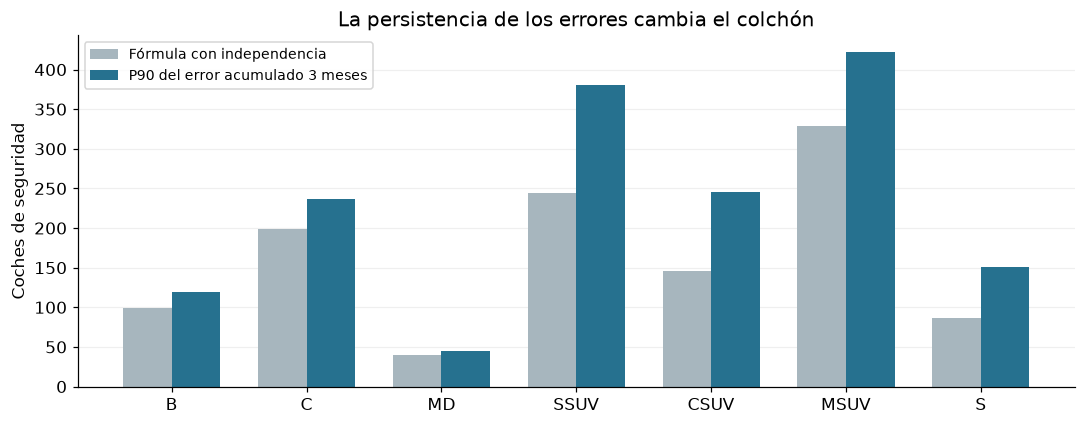

In [15]:
seguridad = tablas['seguridad']
display(seguridad.round(2))
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(7)
ax.bar(x-.18, seguridad.formula_independiente, width=.36, color='#A7B6BE', label='Fórmula con independencia')
ax.bar(x+.18, seguridad.cuantil_error_tres_meses, width=.36, color='#26718F', label='P90 del error acumulado 3 meses')
ax.set(xticks=x, xticklabels=SEGMENTOS, ylabel='Coches de seguridad', title='La persistencia de los errores cambia el colchón')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(salida/'01_stock_seguridad.png', dpi=160)
plt.show(); plt.close(fig)

### 4. La cuenta de cuánto pedir

Al cierre del mes t se conoce el stock Sₜ y las dos próximas llegadas comprometidas. Proyectamos:

**Stock proyectado a t+2 = Sₜ + Lₜ₊₁ + Lₜ₊₂ − demanda prevista t+1 − demanda prevista t+2.**

Después pedimos:

**Llegada t+3 = máximo(0, demanda prevista t+3 + SS − stock proyectado t+2).**

Seguimos literalmente la fórmula del caso y redondeamos el pedido hacia arriba para obtener coches enteros. Si ya vienen demasiados coches, el pedido puede ser cero.

La proyección puede salir negativa: representa un **déficit previsto**, no stock físico negativo. En el bloque de simulación el inventario real se limita a lo disponible y los compradores no atendidos se pierden en ese mes. La fórmula puede pedir más tarde para cubrir el déficit proyectado, pero no recupera por sí sola aquellas ventas. Conviene vigilar este efecto al diseñar una política mejor.

Primero reproducimos el ejemplo de la tabla 3, cuyas llegadas y demandas son didácticas. No usamos sus 700 coches como pipeline real de MSUV.

In [16]:
pedido, proyectado = pedido_a_tres_meses(np.array([536]), np.array([[700], [700]]),
                                       np.array([[550], [600]]), np.array([850]), np.array([222]))
print('Ejemplo del caso: stock proyectado =', proyectado[0], '; llegada pedida para marzo =', pedido[0])
assert proyectado[0] == 786 and pedido[0] == 286
display(tablas['calculo_marzo'].round(1))

Ejemplo del caso: stock proyectado = 786 ; llegada pedida para marzo = 286


,segmento,stock_diciembre_A012,llegadas_enero_febrero,demanda_enero_febrero,stock_proyectado_febrero,demanda_marzo,stock_seguridad,pedido_decidido_diciembre_llega_marzo
0,B,97.0,180,256.1,20.9,137.9,120,238
1,C,1107.0,982,557.3,1531.7,298.8,237,0
2,MD,125.0,42,88.5,78.5,46.1,46,14
3,SSUV,0.0,498,870.3,-372.3,475.8,381,1230
4,CSUV,1011.0,1050,360.0,1701.0,204.4,245,0
5,MSUV,536.0,1362,1026.3,871.7,596.8,422,148
6,S,1.0,62,98.6,-35.6,57.8,151,245


### 5. Por qué añadimos enero–marzo de A014

Los pedidos de octubre, noviembre y diciembre A013 llegarán en enero, febrero y marzo A014. Si al terminar septiembre dejáramos de mirar el futuro, el simulador podría dejar de producir artificialmente y dar una imagen engañosa del cierre anual.

No hay datos ni calendario A014. Prolongamos el central vigente del bloque de escenarios: repetimos el patrón y calendario del primer trimestre A013, eliminamos su caída posterior al adelanto, avanzamos doce meses la tendencia del modelo y mantenemos la cuota prevista de cierre de A013. La macro del central se mantiene; los otros indicadores del primer trimestre se repiten. Es una **continuación supuesta**, etiquetada en cada fila.

Las réplicas de demanda siguen terminando en diciembre A013. Estos tres meses adicionales solo sirven para decidir pedidos al final del año; no inventamos ventas realizadas ni resultados económicos A014. Probamos una continuación un 25% inferior y superior. Afectará a producción y coches en camino al cierre, aunque todavía no hayan llegado a la red.

In [17]:
horizonte = tablas['horizonte']
demanda_horizonte = horizonte.groupby(['mes_plan', 'segmento']).prevision.sum().unstack('segmento')[SEGMENTOS]
display(demanda_horizonte.round(1))
assert demanda_horizonte.shape == (15, 7)
assert horizonte.loc[horizonte.mes_plan > 12, 'continuacion_supuesta'].all()

segmento,B,C,MD,SSUV,CSUV,MSUV,S
mes_plan,,,,,,,
1,129.1,284.7,45.2,432.1,180.4,510.7,50.5
2,127.0,272.5,43.3,438.2,179.6,515.6,48.1
3,137.9,298.8,46.1,475.8,204.4,596.8,57.8
4,136.8,294.2,70.3,451.0,176.6,582.5,60.9
5,133.8,291.4,68.3,488.9,194.5,619.5,66.4
6,146.4,319.0,73.2,515.8,200.9,642.1,62.1
7,149.6,339.1,75.0,544.4,212.5,716.9,60.5
8,126.7,282.9,63.0,484.3,169.8,497.8,60.6
9,132.2,298.7,67.0,528.7,176.0,551.7,55.7


### 6. El plan inicial común

Construimos el plan con la **demanda media central**, no con una réplica afortunada. Avanzamos mes a mes, calculamos stock esperado y dejamos por escrito los pedidos que haríamos si el año siguiera esa media. Para este cálculo determinista no añadimos transfers: sus decisiones se harán al aparecer un déficit en el bloque de simulación.

Los pedidos son enteros; la demanda y el stock esperado pueden ser decimales porque son valores medios. En cada réplica del bloque de simulación todas las unidades serán enteras.

La tabla siguiente indica **mes de fabricación**. Sus doce filas corresponden a fabricación dentro de A013, incluida la que llegará en A014. La tabla de llegadas A013 es distinta: incluye barcos previos y el pedido de marzo decidido al cerrar A012. No sumes ambas tablas como si fueran coches diferentes.

In [18]:
plan_tabla = tablas['plan_central']
fabricar = plan_tabla.pivot(index='mes', columns='segmento', values='fabricar_plan_inicial')[SEGMENTOS]
display(fabricar)
llegadas = pd.DataFrame(plan['llegadas'][:12], columns=SEGMENTOS, index=pd.Index(range(1, 13), name='Mes de llegada A013'))
display(llegadas)
display(plan_tabla[plan_tabla.mes.isin([1, 10, 11, 12])][['mes', 'segmento', 'fabricar_plan_inicial', 'anio_llegada', 'mes_llegada']])
print('Fabricación inicial prevista dentro de A013:', int(fabricar.to_numpy().sum()))
print('Llegadas iniciales previstas dentro de A013:', int(llegadas.to_numpy().sum()))
print('Fabricación A013 que llegará a A014:', int(plan['llegadas'][12:].sum()))

segmento,B,C,MD,SSUV,CSUV,MSUV,S
mes,,,,,,,
1,136,0,70,267,0,582,42
2,134,0,69,300,0,620,50
3,147,0,73,516,0,642,62
4,149,248,75,544,0,717,60
5,127,283,63,485,0,497,61
6,132,299,67,528,0,552,55
7,136,300,67,559,73,627,64
8,135,299,66,562,197,643,55
9,138,304,67,581,208,693,53


,B,C,MD,SSUV,CSUV,MSUV,S
Mes de llegada A013,,,,,,,
1,90,491,21,249,525,681,31
2,90,491,21,249,525,681,31
3,238,0,14,1230,0,148,245
4,136,0,70,267,0,582,42
5,134,0,69,300,0,620,50
6,147,0,73,516,0,642,62
7,149,248,75,544,0,717,60
8,127,283,63,485,0,497,61
9,132,299,67,528,0,552,55


,mes,segmento,fabricar_plan_inicial,anio_llegada,mes_llegada
0,1,B,136,A013,4
1,1,C,0,A013,4
2,1,MD,70,A013,4
3,1,SSUV,267,A013,4
4,1,CSUV,0,A013,4
5,1,MSUV,582,A013,4
6,1,S,42,A013,4
63,10,B,135,A014,1
64,10,C,294,A014,1
65,10,MD,65,A014,1


Fabricación inicial prevista dentro de A013: 20615
Llegadas iniciales previstas dentro de A013: 20530
Fabricación A013 que llegará a A014: 6136


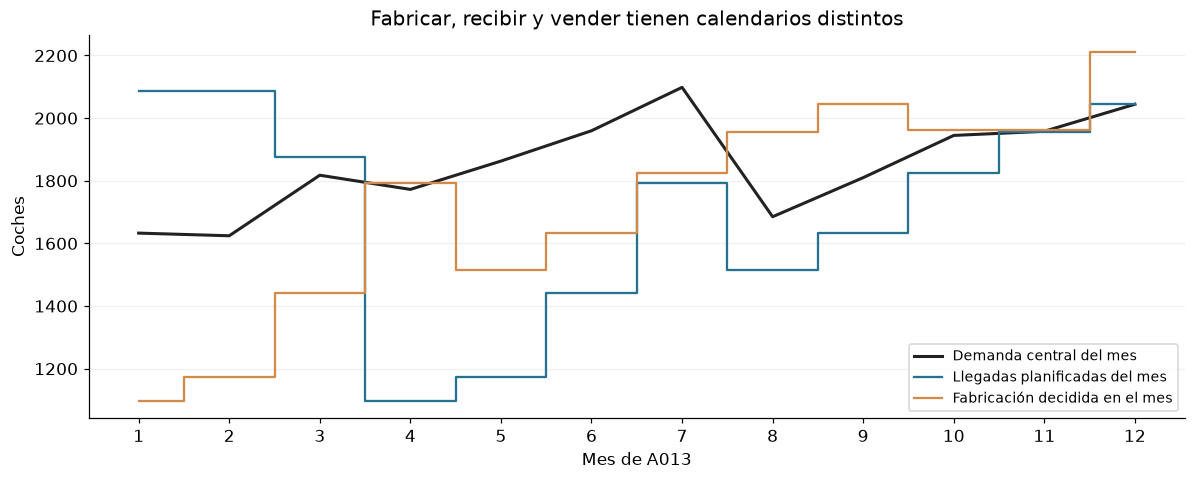

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(range(1, 13), plan['media'][:12].sum(axis=1), color='#222222', lw=2, label='Demanda central del mes')
ax.step(range(1, 13), plan['llegadas'][:12].sum(axis=1), where='mid', color='#26718F', label='Llegadas planificadas del mes')
ax.step(range(1, 13), plan['llegadas'][3:].sum(axis=1), where='mid', color='#D18A4A', label='Fabricación decidida en el mes')
ax.set(xticks=range(1, 13), xlabel='Mes de A013', ylabel='Coches', title='Fabricar, recibir y vender tienen calendarios distintos')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=.2)
fig.tight_layout(); fig.savefig(salida/'02_fabricacion_llegadas_demanda.png', dpi=160)
plt.show(); plt.close(fig)

### 7. Capacidad y transfers: reglas que usará el bloque de simulación

No hay un dato de capacidad de fábrica. Suponemos una capacidad mensual por segmento igual a **1,25 × el mayor pedido mensual del plan inicial A013**, redondeada hacia arriba. Es una proxy diseñada para que el plan central sea factible, no capacidad observada. No modelamos una restricción compartida entre segmentos.

El optimista dispone de un 20% adicional sobre esa proxy, según el supuesto del bloque de escenarios. Si al revisar se pide más de lo que puede fabricarse, el exceso no se fabrica. La parada pesimista elimina producción de MSUV en junio, después de aplicar capacidad; la falta llegará a septiembre. Registraremos por separado ambas restricciones.

Si falta stock, suponemos que se puede traer por transfer el **50% del déficit**, redondeado hacia abajo. No tenemos inventario europeo ni contratos que garanticen esa disponibilidad. El transfer llega directamente para su comprador en ese mes, sin permanecer almacenado en nuestra red.

Para evitar transfers que ya son deficitarios antes de otros costes, solo se permiten cuando beneficio bruto base − VM fresco − costes adicionales del escenario − 20% del beneficio bruto base es positivo. El 20% procede del caso; el resto utiliza fichas y proxies del bloque de escenarios. Es una regla incremental de decisión, no el margen anual del bloque de costes. Las ventas locales y la fabricación aún no se optimizan por rentabilidad: se verá al evaluar costes.

In [20]:
display(tablas['capacidad'])
display(tablas['politica_transfers'][['escenario', 'segmento', 'margen_incremental_transfer_proxy', 'transfer_permitido']].round(2))
assert (tablas['capacidad'].capacidad_nominal_supuesta >= tablas['capacidad'].max_pedido_plan_A013).all()

,segmento,max_pedido_plan_A013,capacidad_nominal_supuesta
0,B,149,187
1,C,309,387
2,MD,75,94
3,SSUV,658,823
4,CSUV,229,287
5,MSUV,731,914
6,S,71,89


,escenario,segmento,margen_incremental_transfer_proxy,transfer_permitido
0,Pesimista,B,-3207.72,False
1,Pesimista,C,-1938.78,False
2,Pesimista,MD,-376.76,False
3,Pesimista,SSUV,-1504.17,False
4,Pesimista,CSUV,-128.08,False
5,Pesimista,MSUV,-644.54,False
6,Pesimista,S,-1652.49,False
7,Central,B,-243.40,False
8,Central,C,632.60,True
9,Central,MD,2531.80,True


### 8. Sensibilidad del plan antes de simular

Recalculamos una hipótesis cada vez: pipeline ±25%, seguridad ×0,5/×1,5 y continuación A014 ±25%. Se reconstruye el plan común para cada alternativa; todavía no son resultados de ventas o costes.

En el bloque de simulación, al comparar variantes operativas, mantendremos fija la capacidad física de la fábrica base. Cambiar el colchón o una estimación de barcos no amplía una fábrica.

Estas comparaciones ayudan a priorizar información: confirmar barcos y cartera de entregas puede cambiar más la decisión inmediata que ajustar un coeficiente pequeño del modelo.

In [21]:
display(tablas['sensibilidad_plan'].query('segmento == "TOTAL"').round(1))
metodo = json.loads((salida/'metodo.json').read_text())
assert metodo['fuentes_sha256'] == huellas()
assert (plan['llegadas'] >= 0).all()
assert (plan_tabla.stock_cierre_esperado >= 0).all()
print('Plan, hipótesis y huellas guardados. Fuentes originales sin cambios.')

,hipotesis,multiplicador,segmento,llegadas_enero_febrero,llegada_marzo,fabricar_A013_plan_inicial,llegadas_A014_comprometidas
7,Pipeline,0.8,TOTAL,3134,2409,20960,6136
15,Pipeline,1.0,TOTAL,4176,1875,20615,6136
23,Pipeline,1.2,TOTAL,5222,1533,20051,6136
31,Seguridad,0.5,TOTAL,4176,1388,20303,6136
39,Seguridad,1.0,TOTAL,4176,1875,20615,6136
47,Seguridad,1.5,TOTAL,4176,2433,20856,6136
55,Continuación A014,0.8,TOTAL,4176,1875,19081,4602
63,Continuación A014,1.0,TOTAL,4176,1875,20615,6136
71,Continuación A014,1.2,TOTAL,4176,1875,22149,7670


Plan, hipótesis y huellas guardados. Fuentes originales sin cambios.


In [22]:
marzo = tablas['calculo_marzo'].set_index('segmento')
texto = '\n'.join([
    '### Conclusión del plan de producción', '',
    f'- Plan inicial de fabricación A013: **{fmt(plan["llegadas"][3:].sum())}** coches; **{fmt(plan["llegadas"][12:].sum())}** de ellos llegarán a A014.',
    f'- Llegadas enero–febrero supuestas: **{fmt(plan["llegadas"][:2].sum())}** coches. Marzo se decide al cerrar A012 y queda común en todas las réplicas.',
    '- C y CSUV tienen suficiente stock proyectado para que el pedido de marzo sea cero; no se cancelan los barcos anteriores.',
    f'- SSUV proyecta un déficit de **{fmt(-marzo.loc["SSUV", "stock_proyectado_febrero"])}** coches antes de marzo. El pedido posterior no recupera ventas ya perdidas.',
    '- El colchón incorpora errores acumulados de tres meses; es una protección supuesta, no un óptimo económico ni un servicio garantizado.', '',
    'El plan es reproducible y pasa al bloque de simulación. Antes de convertirlo en una recomendación: confirmar pipeline, contrastar capacidad y mejorar la previsión provisional. El bloque de simulación medirá rupturas, stock y antigüedad; el bloque de costes valorará su coste.', '',
    'Continúa en [Simulación mensual](03_escenarios_produccion_y_simulacion.ipynb#simulacion).'
])
display(Markdown(texto)); (salida/'conclusiones.md').write_text(texto+'\n')

### Conclusión del plan de producción

- Plan inicial de fabricación A013: **20.615** coches; **6.136** de ellos llegarán a A014.
- Llegadas enero–febrero supuestas: **4.176** coches. Marzo se decide al cerrar A012 y queda común en todas las réplicas.
- C y CSUV tienen suficiente stock proyectado para que el pedido de marzo sea cero; no se cancelan los barcos anteriores.
- SSUV proyecta un déficit de **372** coches antes de marzo. El pedido posterior no recupera ventas ya perdidas.
- El colchón incorpora errores acumulados de tres meses; es una protección supuesta, no un óptimo económico ni un servicio garantizado.

El plan es reproducible y pasa al bloque de simulación. Antes de convertirlo en una recomendación: confirmar pipeline, contrastar capacidad y mejorar la previsión provisional. El bloque de simulación medirá rupturas, stock y antigüedad; el bloque de costes valorará su coste.

Continúa en [Simulación mensual](03_escenarios_produccion_y_simulacion.ipynb#simulacion).

991

<a id="simulacion"></a>

## C Simulación mensual

**Objetivo:** ejecutar el plan del [Producción](03_escenarios_produccion_y_simulacion.ipynb#produccion) en las tres historias del bloque de escenarios, con las mismas 1.000 réplicas por escenario, y registrar cada mes fabricación, llegadas, ventas, transfers, pérdidas, stock y edades.

El bloque de producción describe lo que pensamos hacer al comenzar; este notebook muestra qué ocurre cuando la demanda se aparta de la media y solo podemos cambiar llegadas a tres meses vista. Guardamos unidades y días de permanencia para calcular los costes en el bloque de costes.

La base de demanda sigue siendo provisional. Estos resultados sirven para estudiar la política bajo hipótesis concretas; todavía no prueban que sea la mejor decisión para el negocio.

Fuente: enunciado, apartados 7.1, 7.4, 7.6 y 9.3 (enunciado original del caso).

### 1. Qué pasa en un mes

Dentro de cada mes usamos este orden:

1. Llega lo que ya estaba comprometido y se suma al stock local.
2. Se atiende la demanda con los coches más antiguos primero, hasta agotar disponibilidad.
3. Del déficit se cubre la parte permitida por transfer; el resto son ventas perdidas de ese mes.
4. Se registra stock final, edades y tiempo en cada tramo. No se arrastran compradores perdidos como pedidos pendientes.
5. Al cierre se revisa la previsión con información conocida y se pide la llegada de dentro de tres meses.
6. La fábrica aplica capacidad y el posible suceso del mes; lo realmente fabricado queda comprometido para su llegada futura.

Suponemos meses de 30 días, llegadas al principio y ventas locales el día 15. Son simplificaciones explícitas para seguir antigüedad y permanencia. No deducimos días naturales de los años ficticios ni sorteamos un momento diferente por coche.

No añadimos automatriculaciones para liquidar stock: la demanda representa compradores. No optimizamos aún campañas, precios, mezcla de versiones ni rentabilidad por segmento.

In [23]:
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
from src.simulacion import ejecutar_simulacion, verificar_trayectorias, cohortes_iniciales
from src.produccion import cargar_escenarios, preparar_plan
from src.prevision import SEGMENTOS, huellas
from src.escenarios import ORDEN

politica, tablas, trayectorias = ejecutar_simulacion()
salida = RESULTADOS/'06_simulacion_mensual'
fmt = lambda x, n=0: f'{x:,.{n}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titlesize': 13})
print('Registros físicos:', trayectorias['demanda'].size)
print('Dimensiones:', trayectorias['demanda'].shape, '= escenarios × réplicas × meses × segmentos')
print('No se sortea otra demanda: se usan exactamente las réplicas guardadas por el bloque de escenarios.')

Registros físicos: 252000
Dimensiones: (3, 1000, 12, 7) = escenarios × réplicas × meses × segmentos
No se sortea otra demanda: se usan exactamente las réplicas guardadas por el bloque de escenarios.


### 2. Las identidades que nunca deben fallar

**Ventas locales = mínimo(demanda, stock inicial del mes + llegadas).**

**Ventas totales = ventas locales + transfers.**

**Demanda = ventas totales + ventas perdidas.**

**Stock final = stock inicial + llegadas − ventas locales.**

El transfer viene de otro país para su comprador; no sale de nuestro stock local. Restarlo de nuevo provocaría inventario negativo o una falsa desaparición de coches. Las ventas perdidas son la diferencia entre demanda simulada y atendida; esta diferencia se conoce en el experimento, pero no necesariamente se registra completa en la empresa real.

Las unidades son enteras y no negativas. Los tramos de venta por edad deben sumar las ventas, y los coches con más de 180 días deben estar incluidos entre los de más de 90.

In [24]:
demanda_04, datos_04, _ = cargar_escenarios()
plan = preparar_plan(demanda_04, datos_04, politica)
np.testing.assert_array_equal(trayectorias['demanda'], demanda_04)
verificar_trayectorias(trayectorias, plan)
assert np.array_equal(trayectorias['demanda'], trayectorias['ventas']+trayectorias['ventas_perdidas'])
print('Identidades verificadas en', trayectorias['demanda'].size, 'combinaciones mes-segmento-réplica.')

Identidades verificadas en 252000 combinaciones mes-segmento-réplica.


### 3. La revisión no puede conocer el futuro

La fábrica no ve el año simulado completo. Al cerrar cada mes, la política base utiliza **ventas realizadas hasta ese momento**, incluidos los transfers. Compara la suma de los últimos tres meses disponibles con la demanda central de esos mismos meses.

El ratio se limita entre 0,50 y 1,75. La revisión mezcla un 50% del factor anterior y un 50% del nuevo ratio: así no cambia toda la previsión por un solo mes raro. El factor empieza en uno y se calcula por segmento. Se multiplica la previsión central de los meses futuros por ese factor y se aplica la fórmula de pedidos del bloque de producción con el stock realmente disponible y las llegadas ya comprometidas.

**Límite de observación:** si faltan coches, vender pocos no implica que los compradores quisieran pocos. Basarse en ventas puede infravalorar demanda y prolongar faltas. La sensibilidad “Pedidos registrados” supone que también se conocen las solicitudes no atendidas del mes actual. Es una información adicional hipotética, no un dato que encontremos en los CSV.

El escenario no entrega al controlador su demanda futura ni un multiplicador optimista conocido desde enero. Las primeras tres llegadas están congeladas. La producción de enero llega en abril; la de junio, en septiembre. Al comparar sin revisión, mantenemos los pedidos originales y solo aplicamos las restricciones de fábrica.

In [25]:
np.testing.assert_array_equal(trayectorias['llegadas'][:, :, 3:], trayectorias['fabricado'][:, :, :9])
for i in range(3):
    assert (trayectorias['llegadas'][:, :, i] == plan['llegadas'][i]).all()
ejemplo = tablas['ejemplos_mensuales_5_replicas'].query('escenario == "Central" and replica == 0 and segmento == "SSUV"')
display(ejemplo[['mes', 'demanda', 'ventas', 'ventas_perdidas', 'observacion_revision',
                 'factor_revision', 'fabricar_solicitado', 'fabricado', 'llegadas', 'stock_final']].round(2))

,mes,demanda,ventas,ventas_perdidas,observacion_revision,factor_revision,fabricar_solicitado,fabricado,llegadas,stock_final
423,1,521,385,136,385,0.95,193,193,249,0
430,2,363,306,57,306,0.87,190,190,249,0
437,3,380,380,0,380,0.83,361,361,1230,850
444,4,630,630,0,630,0.90,809,809,193,413
451,5,662,632,30,632,1.03,801,801,190,0
458,6,632,496,136,496,1.12,513,513,361,0
465,7,695,695,0,695,1.15,757,757,809,114
472,8,684,684,0,684,1.18,828,823,801,231
479,9,672,672,0,672,1.25,854,823,513,72
486,10,488,488,0,488,1.21,489,489,757,341


### 4. Cómo seguimos la edad de los coches

El fichero inicial da cantidades por tramo, no la edad exacta. Repartimos los coches de 0–90 días en cohortes de **15, 45 y 75** días; los de 91–180, en **105, 135 y 165**; y los de más de 180, en una cohorte de **195**. El reparto es lo más uniforme posible con unidades enteras; si sobra alguna se asigna primero a la cohorte más antigua del tramo.

Cada llegada crea otra cohorte de edad cero. Al vender seguimos **FIFO**: se consume la cohorte más antigua primero. Los que siguen en stock envejecen treinta días; los vendidos tienen la edad inicial del mes más quince días. No cambia el orden de prioridad entre cohortes.

Es una aproximación: clientes podrían pedir una versión concreta incompatible con el coche más antiguo. Tampoco conocemos cuánto tiempo estuvieron almacenados los transfers en otro país; los tratamos como frescos para el gasto de venta y sin permanencia local. Estas hipótesis deben revisarse cuando calculemos el margen.

Comparamos además edades iniciales más jóvenes y más altas dentro de los tramos. Son puntos representativos, no límites de toda la distribución posible de los coches de más de 180 días.

In [26]:
cantidades, edades = cohortes_iniciales(plan['stock_inicial'], politica['edades_iniciales'])
display(pd.DataFrame(cantidades[:, :7], index=SEGMENTOS,
                     columns=[f'{int(a)} días' for a in edades]))
assert (cantidades.sum(axis=1) == plan['stock_inicial'].stock_total.to_numpy()).all()

,195 días,165 días,135 días,105 días,75 días,45 días,15 días
B,0,0,0,0,33,32,32
C,198,94,94,93,210,209,209
MD,51,19,19,19,6,6,5
SSUV,0,0,0,0,0,0,0
CSUV,0,109,109,109,228,228,228
MSUV,35,22,22,22,145,145,145
S,1,0,0,0,0,0,0


### 5. Resultados físicos del año

Las tablas muestran medias de 1.000 años, de modo que pueden contener decimales aunque cada réplica tenga coches enteros. Presentamos demanda, ventas realizables, fabricación, pérdidas y stock; ninguna de esas cantidades sustituye automáticamente a otra.

La fabricación de A013 incluye coches que llegarán en A014. Las llegadas A013 incluyen fabricación anterior. El stock final es diciembre; el stock medio pondera el tiempo de permanencia durante los doce meses.

**Servicio en unidades** es ventas/demanda: una media del 97% indica que se cubre alrededor del 97% de compradores en esas réplicas, no que haya un 97% de probabilidad de evitar todas las rupturas. La cobertura se expresa respecto a demanda media mensual del año. Si el denominador es cero se deja ausente, no se inventa cero cobertura.

Para el total sumamos segmentos dentro de cada réplica y después calculamos percentiles o ratios. Los percentiles y las coberturas por segmento no se suman. Los meses con pérdidas del total cuentan meses con alguna pérdida, no la suma de meses de siete segmentos.

In [27]:
anuales = tablas['resultados_anuales_replicas']
medias = anuales.groupby(['escenario', 'segmento']).mean(numeric_only=True).drop(columns='replica')
columnas = ['demanda', 'ventas', 'ventas_perdidas', 'transfers', 'fabricado', 'llegadas',
            'stock_medio', 'stock_final', 'stock_mas_90', 'stock_mas_180', 'servicio_unidades_pct']
display(medias.loc[(slice(None), 'TOTAL'), columnas].round(1))
display(medias.loc['Central', columnas].round(1))
intervalos = tablas['resumen_anual'].query('segmento == "TOTAL" and metrica in ["ventas", "ventas_perdidas", "stock_final", "fabricado"]')
display(intervalos[['escenario', 'metrica', 'media', 'p05', 'p50', 'p95']].round(1))

,,demanda,ventas,ventas_perdidas,transfers,fabricado,llegadas,stock_medio,stock_final,stock_mas_90,stock_mas_180,servicio_unidades_pct
escenario,segmento,,,,,,,,,,,
Central,TOTAL,22259.1,21729.4,529.7,449.1,19834.1,20050.8,3496.1,1647.5,186.2,157.2,97.6
Optimista,TOTAL,29989.5,28282.1,1707.5,1518.7,27067.5,25236.6,3204.8,1350.2,71.0,48.5,94.3
Pesimista,TOTAL,20344.9,19320.8,1024.0,0.0,17386.0,17950.9,3517.5,1507.1,270.5,230.1,95.0


,demanda,ventas,ventas_perdidas,transfers,fabricado,llegadas,stock_medio,stock_final,stock_mas_90,stock_mas_180,servicio_unidades_pct
segmento,,,,,,,,,,,
B,1631.0,1554.5,76.5,0.0,1545.7,1562.0,166.8,104.5,0.0,0.0,95.5
C,3610.7,3577.9,32.8,32.5,2536.8,2678.4,777.8,240.0,4.7,0.2,99.1
CSUV,2307.1,2299.7,7.3,7.2,1078.8,1580.9,997.5,299.4,154.9,154.9,99.8
MD,750.9,736.9,14.0,13.4,775.4,647.6,85.0,49.1,0.2,0.0,98.1
MSUV,7212.0,7119.9,92.2,91.6,7332.0,6931.0,792.7,438.6,0.0,0.0,98.7
S,695.9,652.9,43.0,42.1,593.4,734.6,136.0,124.7,26.3,2.0,94.7
SSUV,6051.4,5787.5,263.9,262.4,5972.0,5916.4,540.5,391.3,0.0,0.0,95.7
TOTAL,22259.1,21729.4,529.7,449.1,19834.1,20050.8,3496.1,1647.5,186.2,157.2,97.6


,escenario,metrica,media,p05,p50,p95
183,Central,ventas,21729.4,19955.2,21734.5,23648.7
186,Central,ventas_perdidas,529.7,296.9,516.0,811.0
189,Central,fabricado,19834.1,17604.0,19830.0,22079.4
199,Central,stock_final,1647.5,806.6,1624.5,2572.0
391,Optimista,ventas,28282.1,26094.4,28273.0,30640.4
394,Optimista,ventas_perdidas,1707.5,1173.8,1693.0,2285.0
397,Optimista,fabricado,27067.5,24361.4,27041.0,29753.0
407,Optimista,stock_final,1350.2,479.0,1294.0,2367.0
599,Pesimista,ventas,19320.8,17687.6,19307.0,21116.0
602,Pesimista,ventas_perdidas,1024.0,469.0,997.5,1710.0


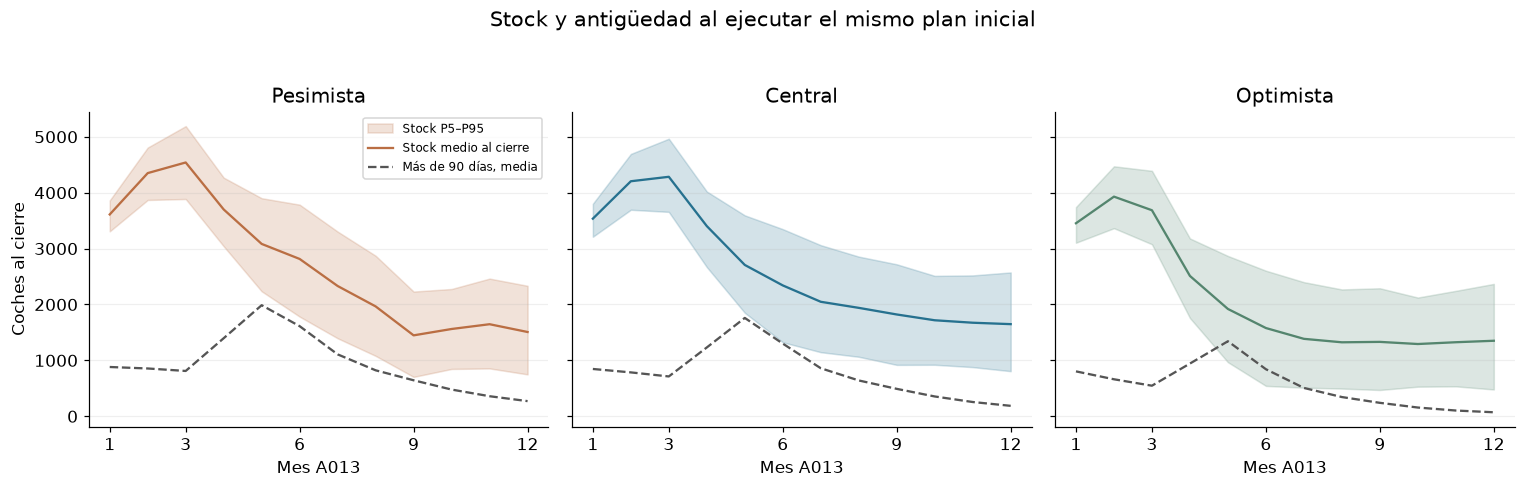

In [28]:
mensuales = tablas['resumen_mensual']
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
colores = {'Pesimista': '#BA6E43', 'Central': '#26718F', 'Optimista': '#54856E'}
for ax, nombre in zip(ejes, ORDEN):
    z = mensuales.query('segmento == "TOTAL" and escenario == @nombre').sort_values('mes')
    ax.fill_between(z.mes, z.stock_final_p05, z.stock_final_p95, color=colores[nombre], alpha=.2, label='Stock P5–P95')
    ax.plot(z.mes, z.stock_final_media, color=colores[nombre], label='Stock medio al cierre')
    ax.plot(z.mes, z.stock_mas_90_media, '--', color='#555555', label='Más de 90 días, media')
    ax.set(title=nombre, xticks=[1, 3, 6, 9, 12], xlabel='Mes A013')
    ax.grid(axis='y', alpha=.2)
ejes[0].set_ylabel('Coches al cierre'); ejes[0].legend(fontsize=8)
fig.suptitle('Stock y antigüedad al ejecutar el mismo plan inicial', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .94)); fig.savefig(salida/'01_stock_y_antiguedad.png', dpi=160)
plt.show(); plt.close(fig)

### 6. Dónde se pierden ventas y qué hace la fábrica

El stock total puede ser abundante y, aun así, faltar el segmento que pide un comprador. No trasladamos un coche C a un cliente SSUV. Por eso se muestran pérdidas por segmento y mes, además del total.

Las llegadas de enero y febrero son hipótesis congeladas; un pedido nuevo no puede reparar sus déficits a tiempo. En el pesimista la parada de junio anula producción MSUV destinada a septiembre. En el optimista la capacidad aumenta, pero no es infinita: podemos pedir más de lo que llega a fabricarse.

Registramos por separado **solicitado = fabricado + reducción por capacidad + producción anulada**. No se convierten automáticamente en pedidos pendientes para el siguiente mes. Las revisiones siguientes responderán al nuevo stock y a las ventas observadas.

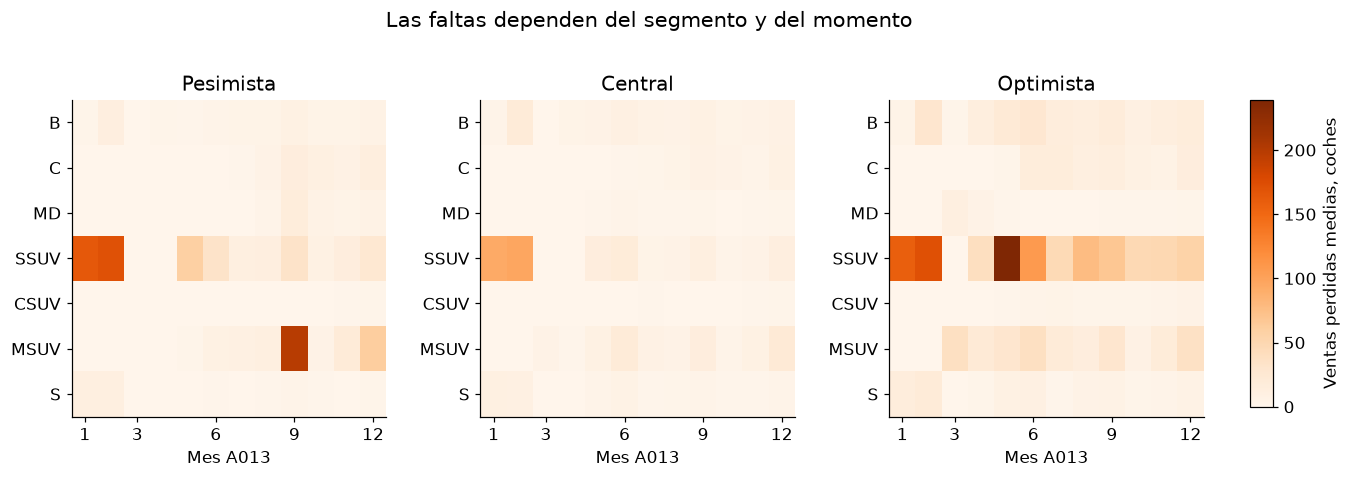

In [29]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.5))
maximo = max(mensuales.loc[mensuales.segmento != "TOTAL", "ventas_perdidas_media"].max(), 1)
for ax, nombre in zip(ejes, ORDEN):
    z = mensuales.query('escenario == @nombre and segmento != "TOTAL"')
    matriz = z.pivot(index='segmento', columns='mes', values='ventas_perdidas_media').reindex(SEGMENTOS)
    im = ax.imshow(matriz, aspect='auto', cmap='Oranges', vmin=0, vmax=maximo)
    ax.set(title=nombre, xticks=[0, 2, 5, 8, 11], xticklabels=[1, 3, 6, 9, 12],
           yticks=range(7), yticklabels=SEGMENTOS, xlabel='Mes A013')
barra = fig.add_axes([.89, .18, .015, .62])
fig.colorbar(im, cax=barra, label='Ventas perdidas medias, coches')
fig.suptitle('Las faltas dependen del segmento y del momento', fontsize=14)
fig.subplots_adjust(top=.80, bottom=.16, wspace=.30, right=.86)
fig.savefig(salida/'02_ventas_perdidas_segmento_mes.png', dpi=160, bbox_inches='tight')
plt.show(); plt.close(fig)

In [30]:
display(medias.loc[(slice(None), 'TOTAL'), ['fabricar_solicitado', 'fabricado', 'reduccion_capacidad', 'produccion_anulada', 'en_camino_cierre']].round(1))
pes = tablas['ejemplos_mensuales_5_replicas'].query('escenario == "Pesimista" and replica == 0 and segmento == "MSUV"')
display(pes[['mes', 'fabricar_solicitado', 'fabricado', 'produccion_anulada', 'llegadas', 'ventas_perdidas']])
assert (trayectorias['fabricado'][0, :, 5, SEGMENTOS.index('MSUV')] == 0).all()
assert (trayectorias['llegadas'][0, :, 8, SEGMENTOS.index('MSUV')] == 0).all()

,,fabricar_solicitado,fabricado,reduccion_capacidad,produccion_anulada,en_camino_cierre
escenario,segmento,,,,,
Central,TOTAL,21163.8,19834.1,1329.7,0.0,5834.3
Optimista,TOTAL,29947.4,27067.5,2880.0,0.0,7881.9
Pesimista,TOTAL,18610.7,17386.0,857.0,367.7,5486.1


,mes,fabricar_solicitado,fabricado,produccion_anulada,llegadas,ventas_perdidas
5,1,0,0,0,681,0
12,2,46,46,0,681,0
19,3,617,617,0,148,0
26,4,678,678,0,0,0
33,5,412,412,0,46,0
40,6,308,0,308,617,0
47,7,1138,914,0,678,0
54,8,760,760,0,412,0
61,9,334,334,0,0,262
68,10,901,901,0,914,0


### 7. Sensibilidad de la política

Usamos las **mismas demandas** en todas las variantes para que las diferencias procedan de la política. Cada alternativa cambia una hipótesis y reconstruye el plan cuando hace falta. La capacidad física base se mantiene; los factores de capacidad y parada de cada escenario también permanecen.

Comparamos: sin revisión; revisión con pedidos registrados; sin transfers; transfer de todo déficit rentable; pipeline ±25%; seguridad mitad o +50%; y edades iniciales jóvenes o mayores. Todas usan las 1.000 réplicas de cada escenario. No buscamos un ganador por margen aquí: atender más ventas puede costar más stock o más transfers.

En las variantes de edad no cambian las cantidades ni el orden FIFO y, por tanto, deberían mantenerse las ventas físicas. Lo que cambia es el tiempo en cada tramo y potencialmente el VM de la venta. Esta diferencia será relevante en el bloque de costes.

,variante,ventas,ventas_perdidas,transfers,stock_medio,stock_mas_90,dias_coche_0_90,dias_coche_91_180
7,Base,21729.4,529.7,449.1,3496.1,186.2,927190.8,245244.5
31,Sin revisión,21690.4,568.7,508.2,3716.4,244.9,997402.9,253948.0
55,Pedidos registrados,21765.4,493.6,419.0,3597.7,189.3,962024.8,246771.9
79,Sin transfers,21112.1,1147.0,0.0,3393.4,183.1,891860.2,243753.9
103,Transfer de todo el déficit rentable,22182.6,76.5,841.9,3589.3,189.2,959230.8,246558.3
127,Pipeline -25%,21611.5,647.6,541.4,3144.3,99.9,875625.7,200487.4
151,Pipeline +25%,21831.3,427.8,362.5,3905.3,315.3,985245.0,295239.5
175,Seguridad mitad,21359.2,899.9,746.8,3060.6,166.5,778581.3,237377.5
199,Seguridad +50%,21917.8,341.3,298.3,3985.1,222.9,1088751.7,257903.7
223,Edades iniciales jóvenes,21729.4,529.7,449.1,3496.1,186.2,944642.1,230651.5


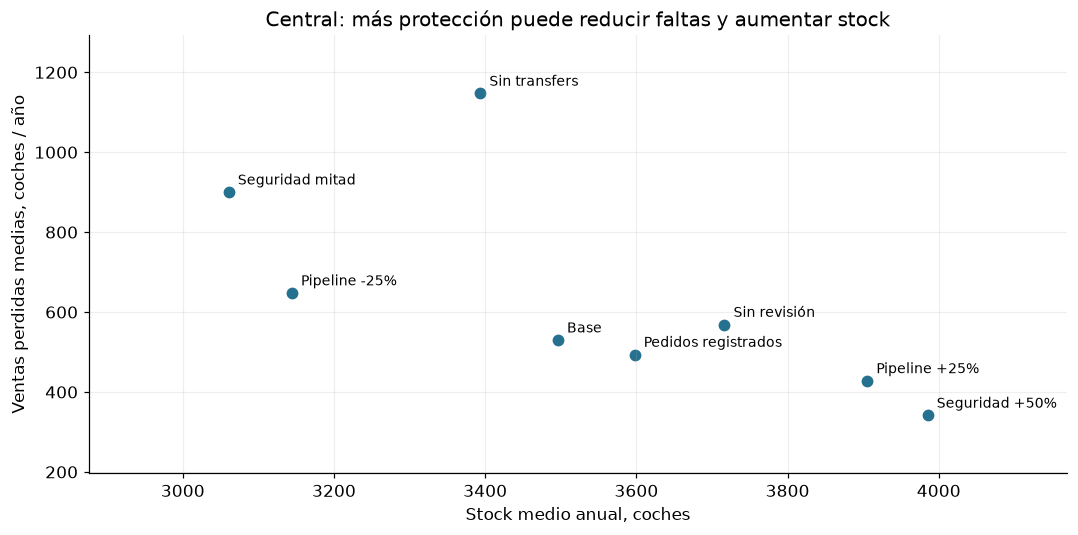

In [31]:
sensibilidad = tablas['sensibilidad_operativa']
display(sensibilidad.query('segmento == "TOTAL" and escenario == "Central"')[
    ['variante', 'ventas', 'ventas_perdidas', 'transfers', 'stock_medio', 'stock_mas_90',
     'dias_coche_0_90', 'dias_coche_91_180']].round(1))
z = sensibilidad.query('segmento == "TOTAL" and escenario == "Central"')
mostrar = z[z.variante.isin(['Base', 'Sin revisión', 'Pedidos registrados', 'Sin transfers',
                           'Pipeline -25%', 'Pipeline +25%', 'Seguridad mitad', 'Seguridad +50%'])]
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(mostrar.stock_medio, mostrar.ventas_perdidas, s=45, color='#26718F')
for _, r in mostrar.iterrows():
    ax.annotate(r.variante, (r.stock_medio, r.ventas_perdidas), xytext=(6, 5), textcoords='offset points', fontsize=9)
ax.set(xlabel='Stock medio anual, coches', ylabel='Ventas perdidas medias, coches / año',
       title='Central: más protección puede reducir faltas y aumentar stock')
ax.margins(x=.20, y=.18); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(salida/'03_sensibilidad_stock_y_perdidas.png', dpi=160)
plt.show(); plt.close(fig)

### 8. Qué guardamos para calcular costes en el bloque de costes

La simulación conserva **ventas por edad al vender**, días-coche de 0–90 y 91–180, y nuevos vencimientos del crédito. Un día-coche es un coche que permanece un día: diez coches durante quince días son 150 días-coche.

Solo registramos permanencia de A013. Un coche que ya tenía 195 días al empezar no vuelve a generar los 180 días anteriores. Al cruzar el día 180, cesa el crédito contemplado por el caso y se registra el nuevo vencimiento; uno ya vencido en A012 no vuelve a vencer en enero.

El bloque de costes podrá multiplicar días-coche por las tasas del caso, asignar VM por edad, cargar costes de transfer y escenario, y separar gasto real de coste de oportunidad. **La devolución del principal del crédito será una necesidad de caja, no un gasto que se reste otra vez al margen.**

Hay una ausencia importante: CSUV no tiene VM observado para más de 180 días. Si se venden coches así, hará falta una hipótesis explícita y sensibilidad. Aquí conservamos la cantidad; no rellenamos el dato económico faltante silenciosamente.

In [32]:
display(medias.loc['Central', ['ventas_0_90', 'ventas_91_180', 'ventas_mas_180',
                              'dias_coche_0_90', 'dias_coche_91_180', 'vencimientos_credito_nuevos']].round(1))
csuv_viejo = medias.loc[('Central', 'CSUV'), 'ventas_mas_180']
display(Markdown(f'En el central se venden de media **{fmt(csuv_viejo)} CSUV con más de 180 días**. Su VM no se conoce en la ficha y queda pendiente del bloque de costes.'))

,ventas_0_90,ventas_91_180,ventas_mas_180,dias_coche_0_90,dias_coche_91_180,vencimientos_credito_nuevos
segmento,,,,,,
B,1539.9,14.6,0.0,59811.4,224.0,0.0
C,1510.5,1665.1,402.3,180247.1,90444.4,204.5
CSUV,415.5,1115.4,768.9,145200.6,139806.0,923.8
MD,595.6,64.3,77.1,25326.9,3349.1,26.1
MSUV,6907.7,177.2,35.0,282090.2,2748.2,0.0
S,482.6,156.4,13.9,40285.4,8332.8,14.9
SSUV,5764.9,22.7,0.0,194229.1,339.8,0.0
TOTAL,17216.6,3215.6,1297.1,927190.8,245244.5,1169.3


En el central se venden de media **769 CSUV con más de 180 días**. Su VM no se conoce en la ficha y queda pendiente del bloque de costes.

### 9. Archivos, comprobaciones y reproducción

- `trayectorias_A013.npz`: todas las trayectorias, comprimidas y con etiquetas de escenario, segmento y mes. Es la fuente completa para el bloque de costes.
- `ejemplos_mensuales_5_replicas.csv`: cinco réplicas por escenario para leer el detalle sin abrir una tabla de 252.000 filas. No sustituye al archivo completo.
- `resultados_anuales_replicas.csv`: resultados anuales de las 1.000 réplicas por escenario, con total calculado dentro de cada réplica.
- `resumen_anual.csv` y `resumen_mensual.csv`: medias y rangos condicionados al modelo.
- `sensibilidad_operativa.csv`: comparación de políticas con demandas comunes y capacidad base fija.

La función comprueba identidades de stock, demanda, antigüedad y fabricación en todas las trayectorias. Las pruebas automatizadas también cambian la demanda futura y verifican que ninguna decisión anterior cambie; comprueban FIFO, día 180, transfers, marzo congelado y la parada junio→septiembre.

Reinicia el kernel y ejecuta todo. Si editas `politica_stock.json`, regenera 05 y después 06. Si editas escenarios, primero regenera 04. Las huellas detectan resultados alterados a mano y fuentes cambiadas. El código compartido está en [src/simulacion.py](../src/simulacion.py).

In [33]:
with np.load(salida/'trayectorias_A013.npz', allow_pickle=False) as guardado:
    for campo, valores in trayectorias.items():
        np.testing.assert_array_equal(guardado[campo], valores)
    assert guardado['escenarios'].tolist() == ORDEN
    assert guardado['segmentos'].tolist() == SEGMENTOS
metodo = json.loads((salida/'metodo.json').read_text())
assert metodo['fuentes_sha256'] == huellas()
print('Todas las trayectorias se recuperan sin pérdida; fuentes originales sin cambios.')

Todas las trayectorias se recuperan sin pérdida; fuentes originales sin cambios.


In [34]:
central = medias.loc[('Central', 'TOTAL')]
texto = '\n'.join([
    '### Conclusión de la simulación física', '',
    f'- Central: demanda media **{fmt(central.demanda)}**, ventas **{fmt(central.ventas)}** y pérdidas **{fmt(central.ventas_perdidas)}**; servicio medio de unidades **{fmt(central.servicio_unidades_pct, 2)} %**.',
    f'- Central: stock medio **{fmt(central.stock_medio)}**, stock final **{fmt(central.stock_final)}** y **{fmt(central.stock_mas_90)}** coches de más de 90 días al cierre.',
    '- C y CSUV concentran exceso inicial; SSUV pierde ventas por falta de disponibilidad en los primeros meses. El stock total no sustituye al segmento solicitado.',
    '- Las revisiones responden al pasado; pedidos registrados darían una señal mejor que ventas cuando hay rupturas, pero esa información no está en los datos originales.',
    '- Todas las réplicas parten del mismo plan. La parada de junio afecta a septiembre y las fabricaciones del trimestre final quedan en camino hacia A014.', '',
    '**Simulación física completada y verificada.** No hay un margen anual calculado todavía. El bloque de costes utilizará las ventas por edad, permanencia, transfers y shocks de coste, y explicará la hipótesis necesaria para VM de CSUV viejo.', '',
    'Antes de recomendar producción siguen pendientes mejorar la previsión provisional, confirmar barcos y capacidad y comparar económicamente las políticas.'
])
display(Markdown(texto)); (salida/'conclusiones.md').write_text(texto+'\n')

### Conclusión de la simulación física

- Central: demanda media **22.259**, ventas **21.729** y pérdidas **530**; servicio medio de unidades **97,62 %**.
- Central: stock medio **3.496**, stock final **1.648** y **186** coches de más de 90 días al cierre.
- C y CSUV concentran exceso inicial; SSUV pierde ventas por falta de disponibilidad en los primeros meses. El stock total no sustituye al segmento solicitado.
- Las revisiones responden al pasado; pedidos registrados darían una señal mejor que ventas cuando hay rupturas, pero esa información no está en los datos originales.
- Todas las réplicas parten del mismo plan. La parada de junio afecta a septiembre y las fabricaciones del trimestre final quedan en camino hacia A014.

**Simulación física completada y verificada.** No hay un margen anual calculado todavía. El bloque de costes utilizará las ventas por edad, permanencia, transfers y shocks de coste, y explicará la hipótesis necesaria para VM de CSUV viejo.

Antes de recomendar producción siguen pendientes mejorar la previsión provisional, confirmar barcos y capacidad y comparar económicamente las políticas.

1131